# Change-point detection for request counts

**Question.** The current detector reports `SPIKE` (single windows) and `SUSTAINED` (the longest above-median run). Neither says *where a shift starts and ends*, and the baseline is fitted before any shift is known. Would **change-point detection**, which splits the series into stretches of constant rate, do better?

**Method.** Penalized-likelihood segmentation with a Poisson cost, solved exactly by dynamic programming (optimal partitioning, Jackson et al. 2005; background reading only, not used for this notebook's numbers). A series is cut at *K* points; each segment gets its own rate; the objective is the sum of segment costs plus a penalty per change point. The penalty is `pen_mult × 2·ln(n)` (a BIC-like choice), multiplied by a robust dispersion estimate so that over-dispersed traffic does not create false change points.

**Contents**
1. The detector, checked against brute-force enumeration of all partitions
2. Calibration: false change points in burst-free traffic
3. Experiment A: detection and localization vs the current detector
4. Experiment B: repairing the baseline (the Known Issue)
5. Experiment C: a daily cycle, and a known-profile fix
6. Takeaways

## Setup

In [1]:
from dataclasses import dataclass
from itertools import combinations
from pathlib import Path
from typing import List, Optional
import sys

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import poisson

# Make the package importable from the repository root or from notebooks/.
repo_root = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "pyproject.toml").is_file()
)
sys.path.insert(0, str(repo_root / "src"))

from poisson_log_analyzer import analyze, detect_spikes
from poisson_log_analyzer.detect import _benjamini_hochberg  # private helper, reused for the baseline experiment

plt.rcParams.update({"figure.figsize": (10, 3.5), "axes.grid": True, "grid.alpha": 0.25})

## 1. The detector

For a segment with total count *S* over total exposure *E* (*E* = number of windows when all windows are equal), the Poisson log-likelihood at the best rate *S/E* is `S·ln(S/E) − S` (constants dropped). The cost is `−2·loglik / φ`, where φ is the dispersion estimate (1 for Poisson traffic). `exposure` lets each window have a known relative length or intensity, which Experiment C uses for a daily profile.

The dispersion estimate comes from successive differences of the rate `y/e`, whose variance is `λφ(1/e_t + 1/e_{t-1})`. A level shift only disturbs the few differences at the shift, and the largest 10% are trimmed; the factor 1.15 compensates the trimming. Section 2 checks the estimator.

In [2]:
@dataclass(frozen=True)
class ChangePoints:
    points: List[int]  # window indices where a new segment starts
    dispersion: float  # dispersion estimate used for the penalty (1.0 when not scaled)
    penalty: float  # penalty per change point, including the dispersion factor


def estimate_dispersion(y, e):
    """Robust variance/mean estimate from successive differences of y/e (about 1 for Poisson)."""
    if len(y) < 4:
        return 1.0
    rate = y / e
    d2 = np.diff(rate) ** 2 / (1 / e[1:] + 1 / e[:-1])
    mean_rate = y.sum() / e.sum()
    if mean_rate <= 0:
        return 1.0
    trimmed = np.sort(d2)[: int(0.9 * len(d2))].mean()
    return max(1.0, 1.15 * trimmed / mean_rate)


def poisson_change_points(counts, pen_mult=1.5, exposure=None, scale_by_dispersion=True):
    """Exact optimal partitioning with a Poisson cost; O(n^2)."""
    y = np.asarray(counts, dtype=float)
    n = len(y)
    e = np.ones(n) if exposure is None else np.asarray(exposure, dtype=float) / np.mean(exposure)
    phi = estimate_dispersion(y, e) if scale_by_dispersion else 1.0
    penalty = pen_mult * 2 * np.log(max(n, 2)) * phi
    S = np.concatenate([[0.0], np.cumsum(y)])
    E = np.concatenate([[0.0], np.cumsum(e)])
    best = np.full(n + 1, np.inf)
    best[0] = -penalty  # the first segment is free of the change-point penalty
    prev = np.zeros(n + 1, dtype=int)
    for t in range(1, n + 1):
        s = np.arange(t)
        seg_sum, seg_exp = S[t] - S[s], E[t] - E[s]
        with np.errstate(divide="ignore", invalid="ignore"):
            loglik = np.where(seg_sum > 0, seg_sum * np.log(seg_sum / seg_exp) - seg_sum, 0.0)
        total = best[s] - 2 * loglik / phi + penalty
        k = int(np.argmin(total))
        best[t], prev[t] = total[k], k
    points, t = [], n
    while t > 0:
        t = prev[t]
        if t > 0:
            points.append(int(t))
    return ChangePoints(sorted(points), float(phi), float(penalty))


def segment_rates(counts, points, exposure=None):
    """List of (start, stop, rate) for each segment; rate is per unit of mean exposure."""
    y = np.asarray(counts, dtype=float)
    e = np.ones(len(y)) if exposure is None else np.asarray(exposure, dtype=float) / np.mean(exposure)
    bounds = [0, *points, len(y)]
    return [(a, b, float(y[a:b].sum() / e[a:b].sum())) for a, b in zip(bounds[:-1], bounds[1:])]


def longest_segment_rate(segments):
    """Rate of the longest segment."""
    return max(segments, key=lambda seg: seg[1] - seg[0])[2]


def weighted_median_rate(segments):
    """Window-weighted median of the segment rates: the level where most windows sit."""
    n = sum(b - a for a, b, _ in segments)
    cumulative = 0
    for a, b, rate in sorted(segments, key=lambda seg: seg[2]):
        cumulative += b - a
        if cumulative >= n / 2:
            return rate

**Check against brute force.** For every small series, enumerate all 2^(n−1) ways to cut it, evaluate the same penalized objective, and require that the dynamic program reaches the minimum.

In [3]:
def objective(y, e, cuts, phi, penalty):
    bounds = [0, *cuts, len(y)]
    total = 0.0
    for a, b in zip(bounds[:-1], bounds[1:]):
        seg_sum, seg_exp = y[a:b].sum(), e[a:b].sum()
        loglik = seg_sum * np.log(seg_sum / seg_exp) - seg_sum if seg_sum > 0 else 0.0
        total += -2 * loglik / phi
    return total + penalty * len(cuts)


rng = np.random.default_rng(0)
checked = 0
for n in range(2, 11):
    for _ in range(15):
        y = rng.poisson(rng.uniform(0.5, 12, size=n))
        exposure = rng.uniform(0.5, 2.0, size=n) if rng.random() < 0.5 else None
        e = np.ones(n) if exposure is None else exposure / exposure.mean()
        result = poisson_change_points(y, pen_mult=rng.choice([0.2, 0.5, 1.0, 1.5]), exposure=exposure,
                                       scale_by_dispersion=bool(rng.random() < 0.5))
        brute = min(
            objective(y.astype(float), e, cuts, result.dispersion, result.penalty)
            for k in range(n) for cuts in combinations(range(1, n), k)
        )
        found = objective(y.astype(float), e, result.points, result.dispersion, result.penalty)
        assert abs(found - brute) < 1e-9, (n, y, result.points)
        checked += 1
print(f"dynamic program reached the brute-force optimum on {checked} random series (n = 2..10)")

dynamic program reached the brute-force optimum on 135 random series (n = 2..10)


## 2. Calibration: false change points in burst-free traffic

Share of burst-free series (n = 120, mean 8) with at least one change point, for several penalty multipliers, with and without the dispersion scaling. Over-dispersed traffic is negative binomial with variance = dispersion × mean. The last column checks the dispersion estimator itself.

In [4]:
def nb_counts(mean, dispersion, size, rng):
    if dispersion <= 1:
        return rng.poisson(mean, size)
    return rng.negative_binomial(mean / (dispersion - 1), 1 / dispersion, size)


rng = np.random.default_rng(0)
TRIALS = 200
mults = [1.0, 1.5, 2.0]
print(f"{'dispersion':>10}  " + "  ".join(f"x{m} plain / scaled" for m in mults) + "   estimated dispersion")
for d in [1, 1.5, 2, 3]:
    series = [nb_counts(8, d, 120, rng) for _ in range(TRIALS)]
    cells = []
    for m in mults:
        plain = np.mean([len(poisson_change_points(c, m, scale_by_dispersion=False).points) > 0 for c in series])
        scaled = np.mean([len(poisson_change_points(c, m).points) > 0 for c in series])
        cells.append(f"{plain:>7.1%} / {scaled:>6.1%}")
    est = np.mean([estimate_dispersion(c.astype(float), np.ones(120)) for c in series])
    print(f"{d:>10}  " + "  ".join(f"{cell:>17}" for cell in cells) + f"   {est:>6.2f}")

dispersion  x1.0 plain / scaled  x1.5 plain / scaled  x2.0 plain / scaled   estimated dispersion


         1      8.5% /   8.5%      0.5% /   0.5%      0.0% /   0.0%     1.00


       1.5     38.0% /  20.5%      7.5% /   4.0%      0.5% /   0.0%     1.12


         2     77.0% /  17.0%     26.5% /   2.0%      7.0% /   0.5%     1.41


         3     98.0% /   6.0%     69.5% /   0.5%     38.5% /   0.0%     2.00


## 3. Experiment A: detection and localization

Poisson baseline of 8 requests/window, 120 windows, a burst from window 40. For each burst length and height (100 series each), compare:
- **`analyze()`** (count test + run test, the current detector): *detected* if a flagged spike falls inside the burst, or the sustained run overlaps it;
- **change points** (penalty multiplier 1.5, dispersion-scaled): *one edge* if a change point lies within ±3 windows of the burst start or end, *both edges* if both do.

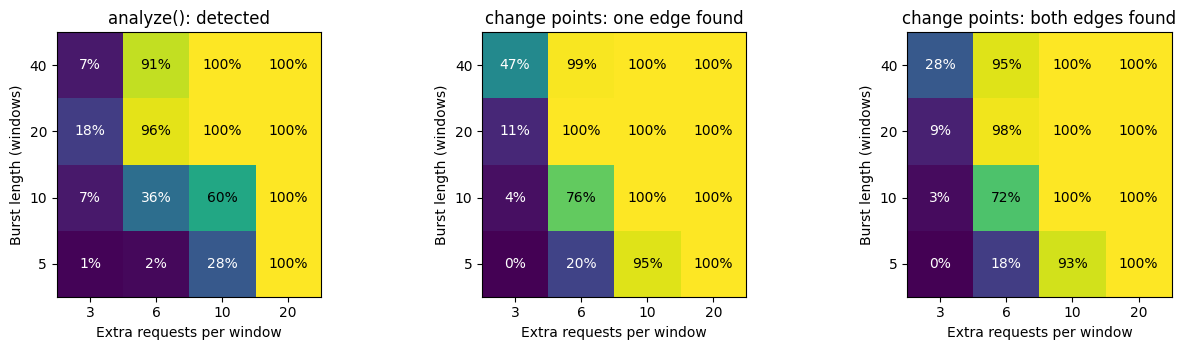

No burst, 300 series: change points 0.3%, analyze() 1.0% false alarms
When both edges were found, the start was off by 0.17 windows on average (median 0), n = 1116


In [5]:
rng = np.random.default_rng(0)
TRIALS_A = 100
lengths = [5, 10, 20, 40]
extras = [3, 6, 10, 20]
START = 40
analyze_hit = np.zeros((len(lengths), len(extras)))
cp_one = np.zeros_like(analyze_hit)
cp_both = np.zeros_like(analyze_hit)
start_errors = []
for i, length in enumerate(lengths):
    for j, extra in enumerate(extras):
        a_hits = one_hits = both_hits = 0
        for _ in range(TRIALS_A):
            counts = rng.poisson(8, 120)
            counts[START:START + length] += extra
            stop = START + length
            result = analyze(counts)
            in_burst = any(START <= w < stop for w in result.spikes.flagged)
            overlaps = result.sustained and result.run.start < stop and result.run.stop > START
            a_hits += in_burst or overlaps
            points = poisson_change_points(counts).points
            near_start = [p for p in points if abs(p - START) <= 3]
            near_stop = [p for p in points if abs(p - stop) <= 3]
            one_hits += bool(near_start or near_stop)
            both_hits += bool(near_start and near_stop)
            if near_start and near_stop:
                start_errors.append(near_start[0] - START)
        analyze_hit[i, j] = a_hits / TRIALS_A
        cp_one[i, j] = one_hits / TRIALS_A
        cp_both[i, j] = both_hits / TRIALS_A

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, grid, title in zip(axes, (analyze_hit, cp_one, cp_both),
                           ("analyze(): detected", "change points: one edge found", "change points: both edges found")):
    ax.imshow(grid, vmin=0, vmax=1, cmap="viridis", origin="lower")
    ax.grid(False)
    ax.set(title=title, xticks=range(len(extras)), xticklabels=extras, yticks=range(len(lengths)), yticklabels=lengths,
           xlabel="Extra requests per window", ylabel="Burst length (windows)")
    for i in range(len(lengths)):
        for j in range(len(extras)):
            ax.text(j, i, f"{grid[i, j]:.0%}", ha="center", va="center", color="white" if grid[i, j] < 0.6 else "black")
plt.tight_layout()
plt.show()

null_series = [rng.poisson(8, 120) for _ in range(300)]
cp_null = np.mean([len(poisson_change_points(c).points) > 0 for c in null_series])
an_null = np.mean([bool(analyze(c).spikes.flagged) or analyze(c).sustained for c in null_series])
print(f"No burst, 300 series: change points {cp_null:.1%}, analyze() {an_null:.1%} false alarms")
print(f"When both edges were found, the start was off by {np.mean(np.abs(start_errors)):.2f} windows on average "
      f"(median {np.median(np.abs(start_errors)):.0f}), n = {len(start_errors)}")

## 4. Experiment B: repairing the baseline

The Known Issue: `detect_spikes` only drops windows it flags on the first pass, so a long modest burst that is never flagged keeps the baseline rate inflated. Idea: read the baseline off the change-point fit. Two rules for choosing the "normal" level from the fitted segments: the rate of the **longest segment**, or the **window-weighted median** of the segment rates (the level where most windows sit).

**B1.** Baseline estimate (true rate 8) when a burst of +6 lasts 10 to 70 of the 120 windows.

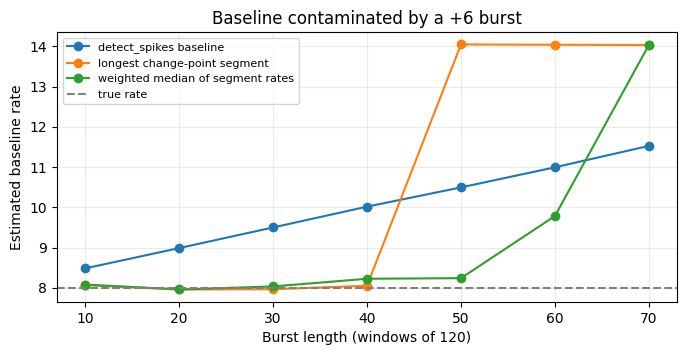

burst length   detect_spikes   longest segment   weighted median   (true rate 8)
          10            8.48              8.07              8.08
          20            8.99              7.96              7.96
          30            9.50              7.96              8.03
          40           10.02              8.05              8.22
          50           10.49             14.05              8.24
          60           10.99             14.04              9.78
          70           11.52             14.03             14.03


In [6]:
rng = np.random.default_rng(0)
burst_lengths = [10, 20, 30, 40, 50, 60, 70]
TRIALS_B = 100
estimates = np.zeros((len(burst_lengths), 3))
for i, length in enumerate(burst_lengths):
    rows = []
    for _ in range(TRIALS_B):
        counts = rng.poisson(8, 120)
        counts[30:30 + length] += 6
        segments = segment_rates(counts, poisson_change_points(counts).points)
        rows.append([detect_spikes(counts, alpha=0.005).rate, longest_segment_rate(segments), weighted_median_rate(segments)])
    estimates[i] = np.mean(rows, axis=0)

fig, ax = plt.subplots(figsize=(8, 3.5))
for k, label in enumerate(["detect_spikes baseline", "longest change-point segment", "weighted median of segment rates"]):
    ax.plot(burst_lengths, estimates[:, k], "o-", label=label)
ax.axhline(8, color="gray", linestyle="--", label="true rate")
ax.set(xlabel="Burst length (windows of 120)", ylabel="Estimated baseline rate", title="Baseline contaminated by a +6 burst")
ax.legend(fontsize=8)
plt.show()
print("burst length   detect_spikes   longest segment   weighted median   (true rate 8)")
for length, row in zip(burst_lengths, estimates):
    print(f"{length:>12}   {row[0]:>13.2f}   {row[1]:>15.2f}   {row[2]:>15.2f}")

**B2.** Does a better baseline find more tall spikes? A 40-window burst of +6 (a third of the series; at 50% or more "normal" is ambiguous, see B1), plus three isolated spikes outside it, with the spike height swept. Recall of the three spikes. "Repaired" = Poisson upper-tail p-values against the weighted-median segment rate, Benjamini–Hochberg at 0.005 (the level `analyze()` gives its count test). Flagged windows that are neither spike nor burst are counted too.

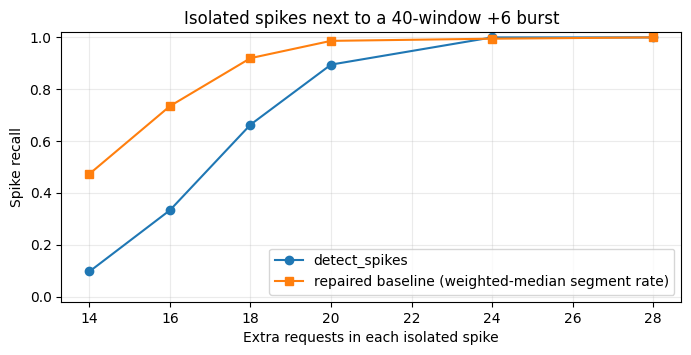

height   recall: detect_spikes / repaired    stray flags per series: detect_spikes / repaired
    14            9.7% /  47.3%                      0.00 /   0.00
    16           33.3% /  73.5%                      0.00 /   0.00
    18           66.3% /  92.0%                      0.00 /   0.01
    20           89.5% /  98.7%                      0.00 /   0.01
    24          100.0% /  99.5%                      0.00 /   0.01
    28          100.0% / 100.0%                      0.00 /   0.01


In [7]:
rng = np.random.default_rng(1)
TRIALS_B2 = 200
spike_windows = [5, 100, 112]
burst = set(range(20, 60))
heights = [14, 16, 18, 20, 24, 28]
recall = np.zeros((len(heights), 2))
stray = np.zeros((len(heights), 2))
for i, height in enumerate(heights):
    for _ in range(TRIALS_B2):
        counts = rng.poisson(8, 120)
        counts[20:60] += 6
        counts[spike_windows] += height
        segments = segment_rates(counts, poisson_change_points(counts).points)
        baseline = weighted_median_rate(segments)
        q = _benjamini_hochberg(poisson.sf(counts - 1, baseline))
        flags = [set(detect_spikes(counts, alpha=0.005).flagged), set(np.flatnonzero(q <= 0.005))]
        for k, flagged in enumerate(flags):
            recall[i, k] += len(flagged & set(spike_windows)) / 3 / TRIALS_B2
            stray[i, k] += len(flagged - set(spike_windows) - burst) / TRIALS_B2

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(heights, recall[:, 0], "o-", label="detect_spikes")
ax.plot(heights, recall[:, 1], "s-", label="repaired baseline (weighted-median segment rate)")
ax.set(xlabel="Extra requests in each isolated spike", ylabel="Spike recall", ylim=(-0.02, 1.02),
       title="Isolated spikes next to a 40-window +6 burst")
ax.legend()
plt.show()
print("height   recall: detect_spikes / repaired    stray flags per series: detect_spikes / repaired")
for height, r, s in zip(heights, recall, stray):
    print(f"{height:>6}   {r[0]:>13.1%} / {r[1]:>6.1%}    {s[0]:>22.2f} / {s[1]:>6.2f}")

## 5. Experiment C: a daily cycle

Three days of 10-minute windows (n = 432) with a smooth daily cycle (rate 8 × (1 + 0.5·sin)), no burst. Smooth variation is not piecewise constant, so the detector should cut it into steps. With a *known* profile as `exposure`, the cycle is divided out. Using the true profile is optimistic; estimating it from the data (without absorbing bursts) is a separate problem.

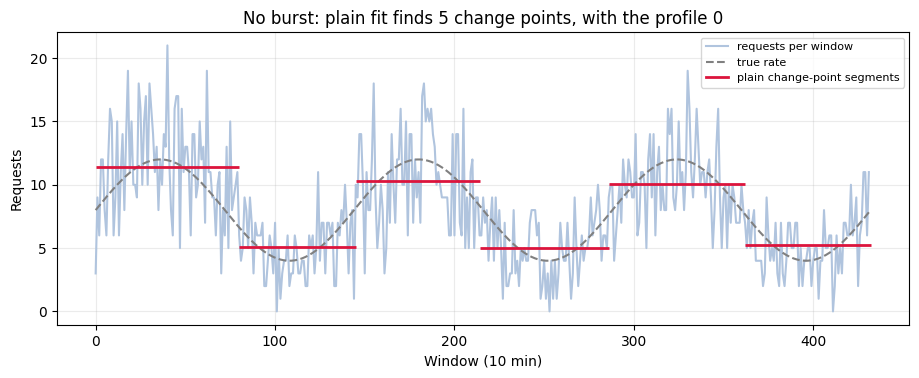

No burst, 50 series: change points per series, plain 5.8, with known profile 0.00
analyze() flags a sustained shift in 82% of them


With the known profile and a +6 burst of 20 windows: both edges found in 86% of series


In [8]:
t = np.arange(432)
profile = 1 + 0.5 * np.sin(2 * np.pi * t / 144)
rng = np.random.default_rng(0)
counts = rng.poisson(8 * profile)

plain = poisson_change_points(counts)
with_profile = poisson_change_points(counts, exposure=profile)

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(t, counts, color="lightsteelblue", label="requests per window")
ax.plot(t, 8 * profile, color="gray", linestyle="--", label="true rate")
for a, b, rate in segment_rates(counts, plain.points):
    ax.hlines(rate, a, b, color="crimson", linewidth=2)
ax.plot([], [], color="crimson", linewidth=2, label="plain change-point segments")
ax.set(xlabel="Window (10 min)", ylabel="Requests", title=f"No burst: plain fit finds {len(plain.points)} change points, with the profile {len(with_profile.points)}")
ax.legend(loc="upper right", fontsize=8)
plt.show()

rng = np.random.default_rng(0)
series = [rng.poisson(8 * profile) for _ in range(50)]
plain_n = [len(poisson_change_points(c).points) for c in series]
profile_n = [len(poisson_change_points(c, exposure=profile).points) for c in series]
print(f"No burst, 50 series: change points per series, plain {np.mean(plain_n):.1f}, with known profile {np.mean(profile_n):.2f}")
print(f"analyze() flags a sustained shift in {np.mean([analyze(c).sustained for c in series]):.0%} of them")

# With a real burst (20 windows, +6) from window 200, with the known profile.
START_C, LEN_C = 200, 20
found = 0
for c in series:
    c = c.copy()
    c[START_C:START_C + LEN_C] += 6
    pts = poisson_change_points(c, exposure=profile).points
    found += any(abs(p - START_C) <= 3 for p in pts) and any(abs(p - (START_C + LEN_C)) <= 3 for p in pts)
print(f"With the known profile and a +6 burst of {LEN_C} windows: both edges found in {found / len(series):.0%} of series")

## 6. Takeaways

- **The detector is correct.** The dynamic program matches brute-force enumeration of all partitions on 135 random series (with and without exposure and dispersion scaling).
- **It detects and locates bursts that the current detector misses or only flags.** Where `analyze()` is weak, the change-point fit is clearly better: for 10-window bursts of +6, both edges are found in 72% of series against 36% detected by `analyze()`; for 5-window bursts of +10, 93% against 28%. When both edges are found the start is off by 0.17 windows on average. Burst-free false alarms: 0.3% against 1.0%.
- **The dispersion scaling is essential.** With over-dispersed traffic (dispersion 3) the plain penalty creates false change points in 70% of burst-free series at the default multiplier; scaled, 0.5%. The estimator slightly under-estimates large dispersions (1.12 for 1.5, 1.41 for 2, 2.0 for 3), so a few percent false alarms remain around dispersion 1.5.
- **A baseline read off the fit repairs the Known Issue, within limits.** The window-weighted median of the segment rates stays within 0.3 of the true rate for bursts up to 50 of 120 windows, where `detect_spikes` drifts from 8.5 to 10.5. Against it, isolated spikes of +14 are found 47% of the time against 10%, with almost no extra false flags. The simpler "longest segment" rule fails as soon as the burst is longer than the stretches left over around it.
- **"Normal" is ambiguous when the abnormal part is half the data or more.** At 60 of 120 windows the baseline flips between the two levels, and at 70 it settles on the burst. No segmentation can resolve that; it needs a prior (for example a known baseline from a previous day).
- **Smooth seasonality breaks it, as it does the run test.** On a daily cycle with no burst, the plain fit reports about 6 change points per series and `analyze()` flags a sustained shift in 82% of series. With the profile known and passed as `exposure`, false change points vanish and a +6 burst of 20 windows has both edges found in 86% of series. Estimating the profile from the data without absorbing bursts is the open problem.

**Decision.** The results justify moving the detector into the package once the open points below are settled; the notebook keeps the experiment. It would give start and end times, dips and multiple events for free.

**Open points before packaging**
- Which "normal" rule to ship (weighted median) and how to warn when the abnormal share reaches half.
- Improve the dispersion estimator (it is biased low at high dispersion) and decide the penalty multiplier (1.5 is used here).
- Estimate the seasonal profile from multi-day data, then re-run Experiment C without the true profile.
- Cost: O(n²) is fine for thousands of windows; a pruned version (PELT) is needed for longer logs.
- How to report segments in the CLI next to `SPIKE` and `SUSTAINED` (a segment table with start, end, rate and ratio to baseline).